# Session 7, Part A: The threshold is a business decision

> **A bank wants to know which customers to phone about a term deposit.** Build the model, watch **accuracy lie to you**, then choose the cut-off for "call", a business decision, not a statistical one.

**How to work:** let Claude write the code; *you* read what the model is doing and make the call.

In [1]:
# --- Load the data -------------------------------------------------
# The data loads from a public link, so there is nothing to upload.
# No internet? Set DATA_URL = "" and upload the file when prompted (Colab only).
DATA_URL = "https://raw.githubusercontent.com/eoinlane/BUU33803-student-notebooks/main/bu7852/session7/data/bank_marketing.csv"

import pandas as pd

if DATA_URL:
    df = pd.read_csv(DATA_URL)
else:
    try:
        from google.colab import files
        print("Upload bank_marketing.csv ...")
        up = files.upload()
        df = pd.read_csv(next(iter(up)))
    except ImportError:
        df = pd.read_csv("data/bank_marketing.csv")   # local fallback (course folder: data/bank_marketing.csv)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## What the columns mean

45,211 past customers, one per row. Features include `age`, `job`, `marital`, `education`, `balance`, `housing`, `loan`, `contact`, `month`, `campaign` (contacts this campaign), `poutcome` (previous outcome)... and the target:

| Column | Meaning |
|---|---|
| `y` | **did the customer subscribe to a term deposit? yes / no** |

> **Know your data:** `duration` is the length of the call that already happened, you only know it *after* you've phoned. A model you'd actually deploy to choose *who to call* can't use it, so we drop it below. That's the kind of leak a good analyst catches before it quietly inflates a model's apparent accuracy.

## Step 1: The baseline: how good is doing nothing?

Before any model: what accuracy do you get by predicting **"no" for everyone** (call nobody)?

In [2]:
baseline = (df['y'] == 'no').mean()
print(f'Predict "no" for everyone -> accuracy = {baseline:.1%}')

Predict "no" for everyone -> accuracy = 88.3%


That's the **accuracy paradox**: a model that calls nobody, sells nothing, and is still about 88% accurate. Any real model has to beat *that*, and accuracy alone won't tell you whether it does.

## Step 2: Build the model, then look inside

> Ask Claude: *"Fit a logistic regression predicting `y` from the other columns, excluding `duration`. One-hot encode the categoricals, scale the features, split 70/30, and show the accuracy and the confusion matrix."*

Accuracy: 0.892


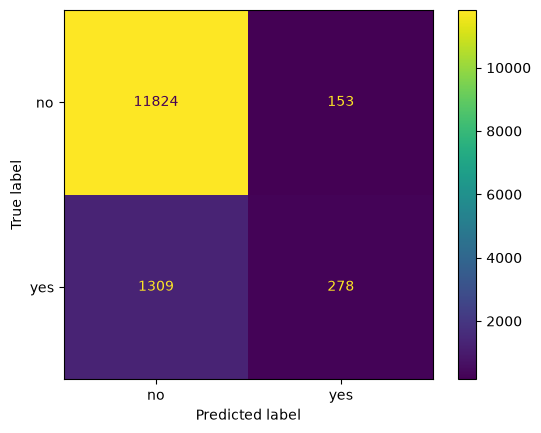

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y = (df['y'] == 'yes').astype(int)
X = pd.get_dummies(df.drop(columns=['y', 'duration']), drop_first=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
pred = clf.predict(Xte)
print('Accuracy:', round(accuracy_score(yte, pred), 3))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=['no', 'yes']).plot(); plt.show()

The accuracy looks solid. Now read the confusion matrix. Look at the **bottom-left** cell, the subscribers the model **missed**. Decent accuracy, and it still walks past most of the buyers.

## Step 3: Precision and recall: what accuracy hid

> Ask Claude: *"Print the precision and recall for the 'yes' class."*

- **Precision**: of everyone the model told us to call, what share actually subscribed? (wasted calls)
- **Recall**: of everyone who would have subscribed, what share did we catch? (missed sales)

In [4]:
from sklearn.metrics import precision_score, recall_score
print('Precision:', round(precision_score(yte, pred), 3))
print('Recall:   ', round(recall_score(yte, pred), 3))

Precision: 0.645
Recall:    0.175


Recall is low. The model is reasonably accurate and still misses most of the buyers, because accuracy is dominated by the roughly 88% who were always going to say no.

## Step 4: Move the threshold

The model doesn't really output yes/no, it outputs a **probability**. `.predict()` just cuts it at 0.5. **You** choose the cut-off. Predict first: to catch more buyers, do you move it up or down?

> Ask Claude: *"Using predicted probabilities, show precision, recall and the share of people called at thresholds 0.5, 0.3 and 0.2."*

In [5]:
prob = clf.predict_proba(Xte)[:, 1]
print(f"{'cut-off':>8} | {'precision':>9} | {'recall':>7} | {'% called':>8}")
for t in [0.5, 0.3, 0.2]:
    p = (prob >= t).astype(int)
    prec = precision_score(yte, p); rec = recall_score(yte, p); called = p.mean()
    print(f'{t:>8} | {prec:>9.3f} | {rec:>7.3f} | {called:>8.1%}')

 cut-off | precision |  recall | % called
     0.5 |     0.645 |   0.175 |     3.2%
     0.3 |     0.528 |   0.312 |     6.9%
     0.2 |     0.449 |   0.423 |    11.0%


Lower the cut-off and **recall rises** (you catch more buyers) but **precision falls** (more of your calls are wasted) and you **phone more people**. None of that is a statistics question. This is exactly the mechanic the Session 8 sample paper's Q12 asks about, in the abstract, on a bank lowering a default-flag threshold.

## Step 5: Decide (this is the point)

Put a price on being wrong and the threshold falls out. Suppose a **subscription is worth €150** and a **wasted call costs €2** of agent time. Estimate the profit at each cut-off, then pick one.

In [6]:
value_sale, cost_call = 150, 2
print(f"{'cut-off':>8} | {'calls':>6} | {'sales':>6} | {'profit (EUR)':>12}")
for t in [0.5, 0.3, 0.2, 0.1]:
    p = (prob >= t).astype(int)
    tp = int(((p == 1) & (yte == 1)).sum())      # subscribers we called
    calls = int(p.sum())                          # everyone we called
    profit = tp * value_sale - calls * cost_call
    print(f'{t:>8} | {calls:>6} | {tp:>6} | {profit:>12,}')

 cut-off |  calls |  sales | profit (EUR)
     0.5 |    431 |    278 |       40,838
     0.3 |    938 |    495 |       72,374
     0.2 |   1496 |    672 |       97,808
     0.1 |   5100 |   1121 |      157,950


### Keep going: is 0.1 really the best?

The table above only tried four round numbers. Before you trust "0.1 is best", push further.

> Ask Claude: *"Repeat the profit calculation for thresholds 0.05, 0.02, 0.01 and 0. What happens to profit?"*

In [7]:
for t in [0.1, 0.05, 0.02, 0.01, 0.0]:
    p = (prob >= t).astype(int)
    tp = int(((p == 1) & (yte == 1)).sum())
    calls = int(p.sum())
    profit = tp * value_sale - calls * cost_call
    print(f'{t:>8} | {calls:>6} | {tp:>6} | {profit:>12,}')

     0.1 |   5100 |   1121 |      157,950
    0.05 |   9952 |   1459 |      198,946
    0.02 |  13009 |   1578 |      210,682
    0.01 |  13513 |   1586 |      210,874
     0.0 |  13564 |   1587 |      210,922


Profit keeps climbing, nearly all the way to calling everyone. That is not a mistake: with a €150 sale and a €2 call, you should call anyone with better than a **break-even chance** of buying.

> Ask Claude: *"Derive algebraically the probability threshold where expected profit per call turns from negative to positive, given a sale is worth €150 and a call costs €2."*

(Expected answer: threshold = cost / value = 2 / 150 ≈ 1.3%, far below anything in the table above.)

**If the textbook answer is "call almost everyone", why might a real bank still run at 0.3 or 0.2?** Name at least two reasons (think: call-centre capacity, contact-frequency/compliance rules, how far you'd trust the model's ranking once you're calling nearly the whole list).

**Write your recommendation to the marketing director in three sentences:** the cut-off you'd actually run (not necessarily the profit-maximising one), why, tying it to both the cost of a wasted call vs a missed sale **and** at least one real-world limit from the last step (capacity, compliance, trust in the model), and one caveat.

In [8]:
# Your three-sentence recommendation to the marketing director:
#


## Step 6: The same mechanic, an audit lens (optional)

A bank's marketing team isn't the only team that owns a threshold. A bank's **AML or fraud-review team** sets a cut-off for which accounts get flagged for manual investigation, exactly the same trade-off: lower the cut-off, catch more real fraud, but spend more investigator time clearing accounts that were fine.

Suppose investigating a flagged account costs **€200** of analyst time, and catching a real fraud case saves **€2,000**. Compute the break-even threshold for this framing the same way you just did for marketing, and compare.

In [9]:
# Same formula (cost / value), very different prices.
marketing_breakeven = cost_call / value_sale
aml_cost_investigate, aml_value_catch = 200, 2000
aml_breakeven = aml_cost_investigate / aml_value_catch
print(f'Marketing break-even: {marketing_breakeven:.1%}  (EUR{cost_call} call vs EUR{value_sale} sale)')
print(f'AML break-even:       {aml_breakeven:.1%}  (EUR{aml_cost_investigate} investigation vs EUR{aml_value_catch:,} catch)')

Marketing break-even: 1.3%  (EUR2 call vs EUR150 sale)
AML break-even:       10.0%  (EUR200 investigation vs EUR2,000 catch)


In [10]:
# Why is the AML break-even so much higher than the marketing one? Same formula,
# very different prices, your one-sentence comparison:
#


## Before you leave

1. Why is accuracy the wrong headline number for this problem?
2. In one sentence: what does moving the threshold down buy you, and what does it cost?
3. Pushing the threshold down revealed the "textbook best" cut-off is near break-even, call almost everyone. What did that reveal about the limits of "maximise expected profit" as a complete answer?
4. Name one other business or audit decision (besides marketing calls and AML flags) that is really a threshold choice.